In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

f=pd.read_csv('amz_uk_price_prediction_dataset.csv')
df=f.copy()

In [3]:
display(df.head(2))
display(df.info())

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


None

In [10]:
# Checking for missing data
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [11]:
popular_prod_cat= df[(df['isBestSeller']==True) & (df['boughtInLastMonth']>0)]['category']
popular_prod_cat

11287                Wearable Technology
11290                Wearable Technology
12896                        Light Bulbs
12897                        Light Bulbs
12898                        Light Bulbs
                       ...              
2405115    Mobile Phones & Communication
2408364    Mobile Phones & Communication
2408700    Mobile Phones & Communication
2431392              Motorbike Batteries
2440120                     Table Tennis
Name: category, Length: 5416, dtype: object

In [12]:
#Popular product categories listed in Amazon UK:
#1. Frequency table
f_table = df['category'].value_counts()
display(f_table)
print('______')
# Calculating the proportion of each unique value in the 'category'
prop_table = df['category'].value_counts(normalize=True)
display(round(prop_table,2))

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

______


category
Sports & Outdoors                         0.34
Beauty                                    0.01
Handmade Clothing, Shoes & Accessories    0.01
Bath & Body                               0.01
Birthday Gifts                            0.01
                                          ... 
Alexa Built-In Devices                    0.00
Motorbike Chassis                         0.00
Plugs                                     0.00
Smart Home Security & Lighting            0.00
Smart Speakers                            0.00
Name: proportion, Length: 296, dtype: float64

In [13]:
#Finding the top 5 most listed product categories
f_table.head(5).index

Index(['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories',
       'Bath & Body', 'Birthday Gifts'],
      dtype='object', name='category')

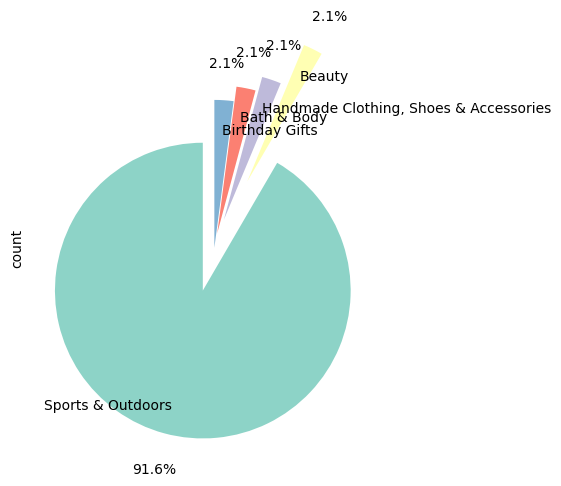

In [14]:
f_table.head(5).plot.pie(autopct='%.1f%%', startangle=90, colors=sns.color_palette("Set3"),
                                       explode=(0.3, 0.5, 0.2, 0.1,0),
                                       pctdistance=1.25, labeldistance=0.8);
plt.show()

In [15]:
#Calculating the mean, median, and mode for the price of products.
mean_price = round(df.price.mean(),2)
median_price = df.price.median()
mode_price = df.price.mode()[0]

mean_price, median_price, mode_price



(np.float64(89.24), 19.09, np.float64(9.99))

In [16]:

df['price'].describe()


count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [17]:
variance_price = round(df.price.var(),2)

min_price = df.price.min()
max_price = df.price.max()
range_price = max_price - min_price

variance_price, range_price,

(119445.49, 100000.0)

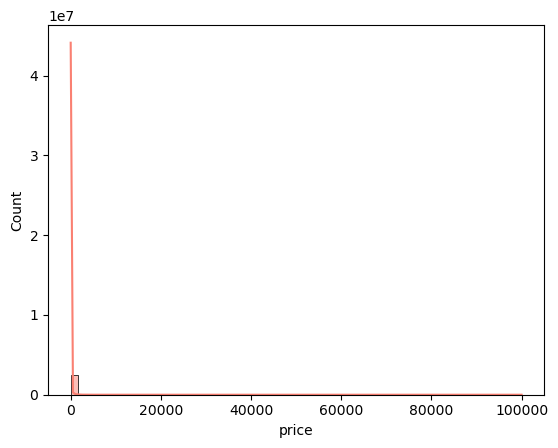

In [30]:
fig, axes = plt.subplots()
sns.histplot(df.price, kde=True, bins=60, color="salmon", ax=axes);
plt.show()

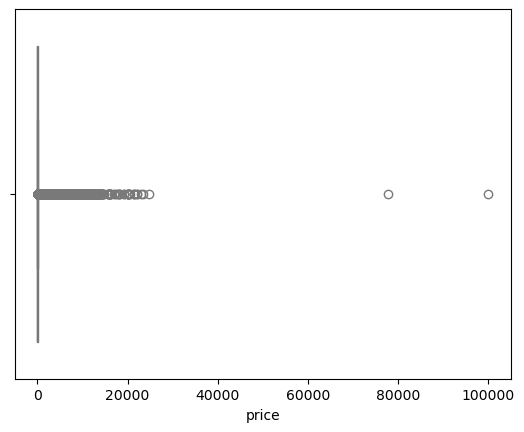

In [31]:
# Plotting a boxplot for the 'SalePrice' column with a light blue color
sns.boxplot(x = df.price, color="lightblue");

In [9]:
df.stars.unique()
f_stars_t = df['stars'].value_counts()
display(f_stars_t)
print('______')

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64

______


In [6]:
mean_s = df.stars.mean()
median_s= df.stars.median()
mode_s=df.stars.mode()
mean_s, median_s, mode_s

(np.float64(2.152836472966066),
 0.0,
 0    0.0
 Name: stars, dtype: float64)

In [6]:
variance_stars = df['stars'].var()
std_dev_stars = df['stars'].std()

quantiles_stars = df['stars'].quantile([0.25, 0.5, 0.75])

round(variance_stars,2), round(std_dev_stars,2), quantiles_stars


(4.82,
 2.19,
 0.25    0.0
 0.50    0.0
 0.75    4.4
 Name: stars, dtype: float64)

In [8]:
skewness_stars = df['stars'].skew()
kurtosis_stars = df['stars'].kurtosis()

round(skewness_stars,2), round(kurtosis_stars,2)

(np.float64(0.08), np.float64(-1.93))

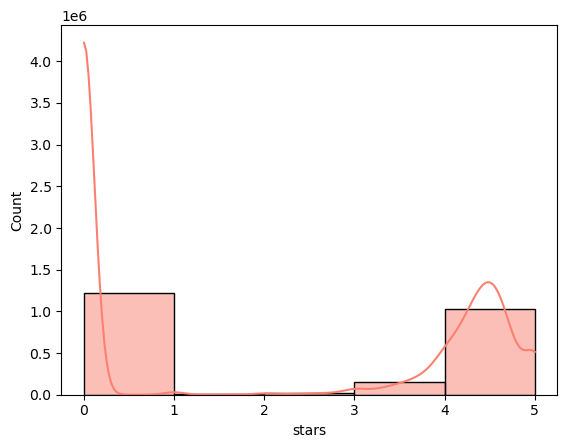

In [9]:
fig, axes = plt.subplots()
sns.histplot(df.stars, kde=True, bins=5, color="salmon", ax=axes);
plt.show()